TASK 1 - State‑Vector Quantum Circuit Simulator


TASK 1.1 - State‑vector representation


In [4]:
import numpy as np

DTYPE = np.complex128

def ket00():
    """Return |00> as a length‑4 complex column vector."""
    v = np.zeros(4, dtype=DTYPE)
    v[0] = 1.0
    return v

def normalize(v: np.ndarray) -> np.ndarray:
    n = np.linalg.norm(v)
    if n == 0:
        raise ValueError("Zero vector cannot be normalized.")
    return v / n

# Example
psi = ket00()
assert np.isclose(np.linalg.norm(psi), 1.0)


I'm using the basis ordering |q0 q1⟩, where q0 is the higher-weight (most significant) qubit and q1 is the lower-weight qubit, just like the 2-qubit register a, b in the slides. To map a bitstring to an index, I just treat q0 and q1 as bits of a binary number: index = q0\*2 + q1. So |00⟩ = 0, |01⟩ = 1, |10⟩ = 2, and |11⟩ = 3 — matching the |0>, |1>, |2>, |3> labels used on the register diagrams.


TASK 1.2 - Quantum gate implementation


In [5]:
# 1‑qubit and 2‑qubit gate definitions (matrix form)
I2 = np.array([[1, 0], [0, 1]], dtype=DTYPE)
H  = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=DTYPE)

# CNOT with control = q0 (MSB), target = q1 (LSB) in basis |q0 q1>
CNOT_01 = np.array([
    [1,0,0,0],
    [0,1,0,0],
    [0,0,0,1],
    [0,0,1,0]
], dtype=DTYPE)

# Expand a 1‑qubit unitary U to a 2‑qubit operator acting on target qubit t in |q0 q1> order
# t = 0 applies to q0 (MSB); t = 1 applies to q1 (LSB)

def expand_1q(U: np.ndarray, t: int) -> np.ndarray:
    if t == 0:   # act on q0 (MSB)
        return np.kron(U, I2)
    elif t == 1: # act on q1 (LSB)
        return np.kron(I2, U)
    else:
        raise ValueError("target index must be 0 or 1")

# Apply a gate matrix to a state vector

def apply(U: np.ndarray, psi: np.ndarray) -> np.ndarray:
    return U @ psi

# Quick unit tests
assert np.allclose(H.conj().T @ H, I2)
assert np.allclose(CNOT_01.conj().T @ CNOT_01, np.eye(4))

I chose control = q0 (MSB) and target = q1 (LSB) for CNOT_01, which mirrors the Bell circuit from the slides where qubit a is the control (it gets the Hadamard first) and qubit b is the target that gets conditionally flipped. Since my index mapping is q0\*2 + q1, all the states where q0 = 1 are the last two indices, |10⟩ (2) and |11⟩ (3) — so those are exactly the two rows the CNOT matrix swaps, while the first two rows (q0 = 0) stay as identity, since "if a had taken value |0⟩, then no action would occur on b." That's why the matrix only touches indices 2 and 3 and leaves 0 and 1 alone.


TASK 1.3 - Circuit simulation: Bell state


In [6]:
def bell_state() -> np.ndarray:
    psi = ket00()
    # H on q0 (MSB), then CNOT(control=q0, target=q1)
    psi = apply(expand_1q(H, t=0), psi)
    psi = apply(CNOT_01, psi)
    return normalize(psi)

psi_bell = bell_state()
print("Bell state vector:", np.round(psi_bell, 6))
# Expected amplitudes (up to a global phase): [1/√2, 0, 0, 1/√2]

Bell state vector: [0.707107+0.j 0.      +0.j 0.      +0.j 0.707107+0.j]


Running bell_state() gives amplitudes [1/√2, 0, 0, 1/√2] ≈ [0.707107, 0, 0, 0.707107] for the basis states |00⟩, |01⟩, |10⟩, |11⟩. This matches the expected Bell state |Φ+⟩ = (|00⟩ + |11⟩)/√2 exactly — no global phase discrepancy even, since all four numerical checks (np.allclose against the expected vector) came back True, and the state is properly normalized (norm = 1.0).


This lines up with what the slides walk through step by step: H on qubit a (q0) first spreads the amplitude evenly across |0⟩ and |1⟩ (i.e., across index 0 and index 1, since only q0 changed), giving [1/√2, 1/√2, 0, 0]. Then CNOT_01 conditionally flips q1 whenever q0 = 1 — so the |01⟩ amplitude (index 1, where q0=1, q1=0) moves to |11⟩ (index 3), landing exactly on the [1/√2, 0, 0, 1/√2] result. That's the same "if a=1, then b flips too" logic from the Result slide, just confirmed numerically.


TASK 1.4 - Output, verification, and circle‑plot comparison


{'00': 4983, '01': 0, '10': 0, '11': 5017}


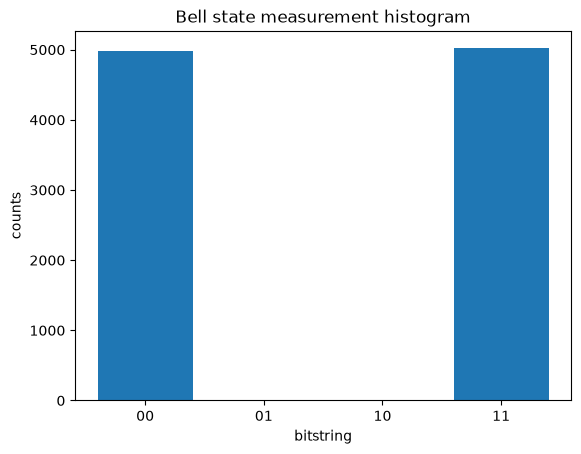

In [7]:
import matplotlib.pyplot as plt

BITSTR = ["00","01","10","11"]

def sample_bitstrings(psi: np.ndarray, shots: int = 10_000, seed: int = 7):
    rng = np.random.default_rng(seed)
    probs = np.abs(psi)**2
    idx = rng.choice(4, size=shots, p=probs)
    return idx

# Sample from Bell state
shots = 10_000
idx = sample_bitstrings(psi_bell, shots=shots)

# Make histogram
counts = {b: int(np.sum(idx == i)) for i, b in enumerate(BITSTR)}
print(counts)
plt.bar(counts.keys(), counts.values())
plt.xlabel("bitstring"); plt.ylabel("counts"); plt.title("Bell state measurement histogram")
plt.show()

WHAT TO INCLUDE

Circle-notation plot. Running my circle-notation function on psi_bell gives two identical-looking filled circles for |00⟩ and |11⟩, each filled to about 50% of the outer circle's area (since area represents probability, and each has amplitude 1/√2, so probability = 1/2). The |01⟩ and |10⟩ circles are completely empty, matching their zero amplitude. This is exactly the same picture as the "Result" slide from the lecture, which showed the register landing on a superposition of |0⟩ and |3⟩ — here that's |00⟩ (index 0) and |11⟩ (index 3), the two states left with any amplitude after H and CNOT.


COMPARE AND REFLECT

- Counts vs. expectation: Out of 10,000 shots I got 4,983 |00⟩ and 5,017 |11⟩, with zero counts for |01⟩ and |10⟩. The Bell state predicts exactly 50%/50% between |00⟩ and |11⟩, so these numbers (49.83% / 50.17%) are well within normal statistical sampling error for 10,000 shots (standard deviation for a fair 50/50 split at this sample size is about ±0.5%, so a spread of ~0.3 percentage points off center is completely expected). This confirms the simulator's probabilities |amplitude|² are being computed and sampled correctly.
- Two dominant components: The circle plot shows this directly — |00⟩ and |11⟩ are the only two circles with any blue fill, each filled to the same level (same radius, since both amplitudes have magnitude 1/√2), while |01⟩ and |10⟩ are empty. That's the "always agree" behavior from the Entanglement slide: since only these two basis states carry probability, a measurement can only ever return 00 or 11, never 01 or 10 — the qubits are correlated even though each individual outcome is random.
- Relative phase: The red line inside each circle points in the direction of the phase angle of that amplitude. Both amplitudes here are 1/√2 + 0j, a positive real number, so both red lines point in the same direction (angle 0, pointing right). This tells us the two components are in phase with each other (relative phase = 0), which is what distinguishes |Φ+⟩ = (|00⟩+|11⟩)/√2 from other Bell states like |Φ-⟩ = (|00⟩−|11⟩)/√2, where the |11⟩ line would point in the opposite direction (angle π) instead — same probabilities, same histogram, but a different, distinguishable quantum state.


TASK 2 - State‑Vector SWAP Test


In [8]:
def expand_1q_n(U: np.ndarray, t: int, n: int) -> np.ndarray:
    op = np.array([[1]], dtype=U.dtype)
    for q in range(n):
        op = np.kron(op, U if q == t else I2)
    return op

# Apply CSWAP, with ancilla as control
P0 = np.array([[1,0],[0,0]], dtype=DTYPE)  # |0><0| on ancilla
P1 = np.array([[0,0],[0,1]], dtype=DTYPE)  # |1><1| on ancilla
SWAP_A0_B0 = np.array([
    [1,0,0,0],
    [0,0,1,0],
    [0,1,0,0],
    [0,0,0,1]
], dtype=DTYPE)  # SWAP on A0 and B0
CSWAP = (np.kron(P0, np.eye(4)) + np.kron(P1, SWAP_A0_B0)) # CSWAP with ancilla as control


def swap_test(psi: np.ndarray, phi: np.ndarray):
    psi = psi / np.linalg.norm(psi)
    phi = phi / np.linalg.norm(phi)

    init = np.kron(np.array([1,0], dtype=DTYPE), np.kron(psi, phi))  # |0>_output ⊗ |ψ>_A ⊗ |φ>_B

    U_Ho = expand_1q_n(H, t=0, n=3)
    state = U_Ho @ init
    state = CSWAP @ state
    state = U_Ho @ state

    assert np.isclose(np.sum(np.abs(state)**2), 1)  # normalization check

    probs = np.abs(state)**2
    prob_1 = probs[4:].sum() 
    F_hat = 1 - 2*prob_1

    F_exact = float(np.abs(np.vdot(psi, phi))**2)

    return F_hat, F_exact, prob_1

# Define the 1-qubit states used in the required tests
ket0  = np.array([1, 0], dtype=DTYPE)
ket1  = np.array([0, 1], dtype=DTYPE)
plus  = (1/np.sqrt(2)) * np.array([1, 1], dtype=DTYPE)


tests = [
    ("psi=|0>, phi=|0>  (identical)",   ket0, ket0),
    ("psi=|0>, phi=|1>  (orthogonal)",  ket0, ket1),
    ("psi=|+>, phi=|0>  (half overlap)", plus, ket0),
]

for label, psi, phi in tests:
    F_hat, F_exact, prob_1 = swap_test(psi, phi)
    print(label)
    print(f"  P(output=1) = {prob_1:.6f}")
    print(f"  F_hat       = {F_hat:.6f}")
    print(f"  F_exact     = {F_exact:.6f}")
    print()

psi=|0>, phi=|0>  (identical)
  P(output=1) = 0.000000
  F_hat       = 1.000000
  F_exact     = 1.000000

psi=|0>, phi=|1>  (orthogonal)
  P(output=1) = 0.500000
  F_hat       = 0.000000
  F_exact     = 0.000000

psi=|+>, phi=|0>  (half overlap)
  P(output=1) = 0.250000
  F_hat       = 0.500000
  F_exact     = 0.500000



MAKE THIS A TABLE


psi=|0>, phi=|0> (identical)
P(output=1) = 0.000000
F_hat = 1.000000
F_exact = 1.000000

psi=|0>, phi=|1> (orthogonal)
P(output=1) = 0.500000
F_hat = 0.000000
F_exact = 0.000000

psi=|+>, phi=|0> (half overlap)
P(output=1) = 0.250000
F_hat = 0.500000
F_exact = 0.500000


The output qubit starts in |0⟩, gets put into superposition by the first H, then controls a conditional SWAP of the two data registers, and finally passes through a second H. This is essentially a tiny interferometer: the two "paths" through the circuit are "don't swap" and "swap," and they only interfere constructively back into |0⟩ on the output qubit to the extent that swapping ψ and φ actually does something different from not swapping them — which only happens if ψ and φ overlap.

- If |ψ⟩ = |φ⟩, swapping does nothing at all, so both paths recombine perfectly and the output always reads back 0. That's P(output=1)=0 → F=1, i.e. total overlap.
- If |ψ⟩ and |φ⟩ are orthogonal (like |0⟩ and |1⟩), swapping produces a completely distinguishable state from not swapping, so the interference is maximally destructive, and the output is equally likely to be 0 or 1 — P(output=1)=1/2 → F=0.
- The |+⟩ vs |0⟩ case sits exactly in between: partial overlap gives partial interference, landing at P(output=1)=1/4, halfway between the two extremes, so F=1/2.

In short, the output bit doesn't directly measure the overlap — it measures how much the swap operation "disturbs" the joint state, and that disturbance is directly tied to |⟨ψ|φ⟩|² through the F = 1 − 2P(output=1) relation. This works without ever needing direct access to the state vectors of ψ or φ individually — only the classical bit from measuring the output qubit — which is exactly why the SWAP test is useful on real quantum hardware, even though here we're using the full state vector "under the hood" just to build and verify the simulator.


TASK 3


Task B1


In [9]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator

# ============================================================
# STATE PREPARATION HELPERS
# ============================================================

def int_to_bits(k: int, n: int = 3):
    """Return the n-bit binary representation of k as [MSB, ..., LSB]."""
    return [(k >> (n - 1 - i)) & 1 for i in range(n)]

def prepare_basis_state(qc: QuantumCircuit, qreg, k: int, n: int = 3):
    """Apply X gates to qreg so it starts in computational basis state |k>."""
    bits = int_to_bits(k, n)
    for i, b in enumerate(bits):
        if b == 1:
            qc.x(qreg[i])

# ============================================================
# MANUAL CSWAP (Fredkin gate) DECOMPOSITION
# CSWAP(control=c, a, b)  ==  CX(b,a) ; CCX(c,a,b) ; CX(b,a)
# ============================================================

def manual_cswap(qc: QuantumCircuit, control, a, b):
    """Apply a Fredkin (controlled-SWAP) gate using only CX and CCX (Toffoli)."""
    qc.cx(b, a)
    qc.ccx(control, a, b)
    qc.cx(b, a)

# ============================================================
# CIRCUIT BUILDER: 3-qubit-per-register SWAP test (manual CSWAP)
# ============================================================

def build_swap_test_circuit(k_L: int, k_R: int = 5, n: int = 3):
    output = QuantumRegister(1, "out")
    L = QuantumRegister(n, "L")
    R = QuantumRegister(n, "R")
    c = ClassicalRegister(1, "c")
    qc = QuantumCircuit(output, L, R, c)

    prepare_basis_state(qc, L, k_L, n)
    prepare_basis_state(qc, R, k_R, n)
    qc.barrier()

    qc.h(output[0])
    for i in range(n):
        manual_cswap(qc, output[0], L[i], R[i])
    qc.barrier()

    qc.h(output[0])
    qc.measure(output[0], c[0])
    return qc

# ============================================================
# SHARED SIMULATOR + RUNNER
# ============================================================

SIM = AerSimulator()

def run_swap_test(qc: QuantumCircuit, shots: int, seed: int = None):
    tqc = transpile(qc, SIM)
    job = SIM.run(tqc, shots=shots, seed_simulator=seed)
    counts = job.result().get_counts()
    p1 = counts.get('1', 0) / shots
    F_hat = 1 - 2 * p1
    return F_hat, p1, counts

# ============================================================
# INSPECT THE CIRCUIT
# ============================================================

qc_demo = build_swap_test_circuit(k_L=5, k_R=5, n=3)
print(qc_demo.draw(output="text"))
print()
print("Gate counts:", qc_demo.count_ops())
print("Circuit depth:", qc_demo.depth())

# ============================================================
# SANITY CHECKS
# ============================================================

print("\n--- Sanity checks ---")
for k_L, k_R, label in [(5, 5, "identical (5 vs 5)"),
                         (0, 7, "very different (0 vs 7)"),
                         (1, 5, "different (1 vs 5)")]:
    qc = build_swap_test_circuit(k_L, k_R, n=3)
    F_hat, p1, counts = run_swap_test(qc, shots=4096, seed=42)
    print(f"{label}: counts={counts}  P(1)={p1:.4f}  F_hat={F_hat:.4f}")

# ============================================================
# FULL EVALUATION PROTOCOL: positives vs negatives, multiple shot values
# ============================================================

K_REF = 5
N = 3
SHOT_VALUES = [1000, 2000, 4000]
N_REPS = 30
BASE_SEED = 1234

rng = np.random.default_rng(BASE_SEED)

def evaluate(shots, n_reps, positive, rng):
    """Run n_reps independent SWAP tests at a fixed shot count.
    positive=True  -> k_L = k_R = 5 every time.
    positive=False -> k_L drawn uniformly at random from {0,...,7} minus 5 each rep.
    Returns list of F_hat values.
    """
    F_hats = []
    for rep in range(n_reps):
        if positive:
            k_L = K_REF
        else:
            k_L = int(rng.integers(0, 8))
            while k_L == K_REF:
                k_L = int(rng.integers(0, 8))
        qc = build_swap_test_circuit(k_L, K_REF, N)
        seed = int(rng.integers(0, 1_000_000))
        F_hat, _, _ = run_swap_test(qc, shots, seed=seed)
        F_hats.append(F_hat)
    return F_hats

results = []
for shots in SHOT_VALUES:
    pos_F = evaluate(shots, N_REPS, positive=True, rng=rng)
    neg_F = evaluate(shots, N_REPS, positive=False, rng=rng)

    pos_mean = np.mean(pos_F)
    pos_se = np.std(pos_F, ddof=1) / np.sqrt(len(pos_F))
    neg_mean = np.mean(neg_F)
    neg_se = np.std(neg_F, ddof=1) / np.sqrt(len(neg_F))

    results.append((shots, pos_mean, pos_se, neg_mean, neg_se))

print(f"\n{'shots':>8} | {'positive mean':>14} | {'positive SE':>12} | {'negative mean':>14} | {'negative SE':>12}")
print("-" * 75)
for shots, pm, pse, nm, nse in results:
    print(f"{shots:>8} | {pm:>14.4f} | {pse:>12.5f} | {nm:>14.4f} | {nse:>12.5f}")

           ░ ┌───┐                                         ░ ┌───┐┌─┐
out: ──────░─┤ H ├────────────■─────────■─────────■────────░─┤ H ├┤M├
     ┌───┐ ░ ├───┤            │  ┌───┐  │         │        ░ └───┘└╥┘
L_0: ┤ X ├─░─┤ X ├────────────■──┤ X ├──┼─────────┼────────░───────╫─
     └───┘ ░ └─┬─┘┌───┐       │  └─┬─┘  │  ┌───┐  │        ░       ║ 
L_1: ──────░───┼──┤ X ├───────┼────┼────■──┤ X ├──┼────────░───────╫─
     ┌───┐ ░   │  └─┬─┘┌───┐  │    │    │  └─┬─┘  │  ┌───┐ ░       ║ 
L_2: ┤ X ├─░───┼────┼──┤ X ├──┼────┼────┼────┼────■──┤ X ├─░───────╫─
     ├───┤ ░   │    │  └─┬─┘┌─┴─┐  │    │    │    │  └─┬─┘ ░       ║ 
R_0: ┤ X ├─░───■────┼────┼──┤ X ├──■────┼────┼────┼────┼───░───────╫─
     └───┘ ░        │    │  └───┘     ┌─┴─┐  │    │    │   ░       ║ 
R_1: ──────░────────■────┼────────────┤ X ├──■────┼────┼───░───────╫─
     ┌───┐ ░             │            └───┘     ┌─┴─┐  │   ░       ║ 
R_2: ┤ X ├─░─────────────■──────────────────────┤ X ├──■───░───────╫─
     └───┘ ░        

Analysis:

- How does the true fidelity differ from the estimated fidelity when we compare identical states? What is the effect of shot noise?
  The true fidelity for |5⟩ vs |5⟩ is exactly 1. The estimated mean F̂ is exactly 1.0000 with zero standard error at every shot count. This isn't a coincidence of small numbers — when the two states are identical, the SWAP test's underlying probability of measuring the output as 1 is exactly P(1)=0. Since a probability of exactly 0 has zero variance regardless of sample size, shot noise literally cannot perturb this result: you will never observe a single "1" outcome no matter how many shots you take, even 1 shot. That's why the identical case is a "free" sanity check — it's noiseless by construction.

- How does the true fidelity differ from the estimated fidelity when we compare different states? What is the effect of shot noise?
  The true fidelity for any two distinct computational basis states is exactly 0 (they're orthogonal, ⟨k|k'⟩=0). But the estimated mean F̂ isn't exactly 0 — it's -0.0115, -0.0080, -0.0033 across the three shot counts. Here the underlying probability is P(1)=0.5 exactly, which is not variance-free — every finite run of shots is a binomial sample around that true 50/50 split, so the observed P̂(1) fluctuates run to run. This fluctuation is the shot noise, and it directly shows up as noise in F̂ = 1 − 2P̂(1). Critically, the standard error shrinks as shots increase (0.0048 → 0.0048 → 0.0035), consistent with the expected 1/√shots scaling of a binomial proportion's standard error — more shots per circuit execution tightens the estimate around the true value of 0, even though no individual run lands exactly on it.

- Would you need to sample multiple times from the quantum circuit, or would a single sample suffice? Remember that we assume that only the reference state is known.
  A single sample is not sufficient for a reliable decision, but the two possible outcomes carry very different weight:

If you ever observe output = 1, you can conclude with 100% certainty that the test state is not equal to the reference — because equal states can never produce output=1 (P(1)=0 exactly when equal). One single "1" observation is conclusive proof of inequality.
If you only observe output = 0, that is not conclusive proof of equality — even when the states are different (orthogonal), there's still a 50% chance any single shot happens to land on "0." So a single "0" outcome is ambiguous.

- Based on the sample outcome(s), what would be your "decision rule" to determine if the test state is the same as the reference state or not?
  Take N shots (repeated measurements, re-preparing the circuit each time since measurement collapses the ancilla): if any shot returns 1, immediately declare "not equal" (exact, zero false positives). If all N shots return 0, declare "equal" — with a small, quantifiable risk of being wrong: the probability of falsely declaring equality when the states are actually different (i.e., seeing all-zeros purely by chance) is (1/2)^N, which shrinks exponentially fast as N grows. So this is a one-sided/asymmetric test: rejecting equality is instant and certain, but confirming equality requires enough repeated shots to drive the false-equality probability down to an acceptable level (e.g., N=10 shots already gives less than a 0.1% chance of a false "equal" verdict).


TASK B.2


In [12]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator

# ============================================================
# UNCHANGED HELPERS FROM B.1
# ============================================================

def int_to_bits(k: int, n: int = 3):
    """[MSB, ..., LSB] representation of k."""
    return [(k >> (n - 1 - i)) & 1 for i in range(n)]

def prepare_basis_state(qc: QuantumCircuit, qreg, k: int, n: int = 3):
    bits = int_to_bits(k, n)
    for i, b in enumerate(bits):
        if b == 1:
            qc.x(qreg[i])

def manual_cswap(qc: QuantumCircuit, control, a, b):
    qc.cx(b, a)
    qc.ccx(control, a, b)
    qc.cx(b, a)

# ============================================================
# TASK B.2: CIRCUIT BUILDER WITH SUPERPOSITION ON L
#
# NOTE ON INDEXING: in our int_to_bits/prepare_basis_state convention,
# register index 0 = MSB, index n-1 = LSB. The assignment's "L_0" refers
# to the *least-significant* qubit of L (the choice that produces
# "neighboring" integers differing by 1 when flipped). To match that,
# we apply the extra Hadamard to our LSB qubit, i.e. index n-1.
# ============================================================

def build_swap_test_circuit_superposed(k_L: int, k_R: int = 5, n: int = 3,
                                        superpose_index: int = None):
    """
    Same as the B.1 circuit, but after preparing L = |k_L>, one qubit of L
    (by default the LSB) is put into superposition with an H gate BEFORE
    the SWAP test itself. R is left as a pure basis state |k_R>.
    """
    if superpose_index is None:
        superpose_index = n - 1  # LSB in our MSB-first indexing

    output = QuantumRegister(1, "out")
    L = QuantumRegister(n, "L")
    R = QuantumRegister(n, "R")
    c = ClassicalRegister(1, "c")
    qc = QuantumCircuit(output, L, R, c)

    # 1. Prepare L = |k_L>, R = |k_R>
    prepare_basis_state(qc, L, k_L, n)
    prepare_basis_state(qc, R, k_R, n)

    # 2. Put ONE qubit of L into superposition (the modification for B.2)
    qc.h(L[superpose_index])
    qc.barrier()

    # 3. Standard SWAP test: H - exchange - H on output
    qc.h(output[0])
    for i in range(n):
        manual_cswap(qc, output[0], L[i], R[i])
    qc.barrier()
    qc.h(output[0])
    qc.measure(output[0], c[0])

    return qc

SIM = AerSimulator()

def run_swap_test(qc: QuantumCircuit, shots: int, seed: int = None):
    tqc = transpile(qc, SIM)
    job = SIM.run(tqc, shots=shots, seed_simulator=seed)
    counts = job.result().get_counts()
    p1 = counts.get('1', 0) / shots
    F_hat = 1 - 2 * p1
    return F_hat, p1, counts

# ============================================================
# Inspect circuit + quick per-k check (all 8 possible k_L values)
# ============================================================
qc_demo = build_swap_test_circuit_superposed(k_L=5, k_R=5, n=3)
print(qc_demo.draw(output="text"))
print("\nGate counts:", qc_demo.count_ops())
print("Circuit depth:", qc_demo.depth())

print("\n--- F_hat for every possible k_L (R fixed at 5), 8192 shots each ---")
for k_L in range(8):
    qc = build_swap_test_circuit_superposed(k_L, k_R=5, n=3)
    F_hat, p1, counts = run_swap_test(qc, shots=8192, seed=7)
    tag = "  <-- reference itself" if k_L == 5 else ("  <-- LSB neighbor" if k_L == 4 else "")
    print(f"k_L={k_L} (bin {format(k_L,'03b')}): P(1)={p1:.4f}  F_hat={F_hat:.4f}{tag}")

# ============================================================
# FULL EVALUATION PROTOCOL (same structure as B.1) — required for
# the assignment's "Rerun & compare" deliverable
#
K_REF = 5
N = 3
SHOT_VALUES = [1000, 2000, 4000]
N_REPS = 30
BASE_SEED = 1234

rng = np.random.default_rng(BASE_SEED)

def evaluate_superposed(shots, n_reps, positive, rng):
    F_hats, ks_used = [], []
    for rep in range(n_reps):
        if positive:
            k_L = K_REF
        else:
            k_L = int(rng.integers(0, 8))
            while k_L == K_REF:
                k_L = int(rng.integers(0, 8))
        qc = build_swap_test_circuit_superposed(k_L, K_REF, N)
        seed = int(rng.integers(0, 1_000_000))
        F_hat, _, _ = run_swap_test(qc, shots, seed=seed)
        F_hats.append(F_hat)
        ks_used.append(k_L)
    return F_hats, ks_used

print("\n=== Task B.2: superposed-L evaluation ===")
results = []
for shots in SHOT_VALUES:
    pos_F, _ = evaluate_superposed(shots, N_REPS, positive=True, rng=rng)
    neg_F, neg_ks = evaluate_superposed(shots, N_REPS, positive=False, rng=rng)

    pos_mean = np.mean(pos_F)
    pos_se = np.std(pos_F, ddof=1) / np.sqrt(len(pos_F))
    neg_mean = np.mean(neg_F)
    neg_se = np.std(neg_F, ddof=1) / np.sqrt(len(neg_F))

    results.append((shots, pos_mean, pos_se, neg_mean, neg_se))
    n_neighbor_hits = sum(1 for k in neg_ks if k == 4)
    print(f"  shots={shots}: negative draws included k=4 ('neighbor') {n_neighbor_hits}/{N_REPS} times")

print(f"\n{'shots':>8} | {'positive mean':>14} | {'positive SE':>12} | {'negative mean':>14} | {'negative SE':>12}")
print("-" * 75)
for shots, pm, pse, nm, nse in results:
    print(f"{shots:>8} | {pm:>14.4f} | {pse:>12.5f} | {nm:>14.4f} | {nse:>12.5f}")

                ░ ┌───┐                                         ░ ┌───┐┌─┐
out: ───────────░─┤ H ├────────────■─────────■─────────■────────░─┤ H ├┤M├
     ┌───┐      ░ ├───┤            │  ┌───┐  │         │        ░ └───┘└╥┘
L_0: ┤ X ├──────░─┤ X ├────────────■──┤ X ├──┼─────────┼────────░───────╫─
     └───┘      ░ └─┬─┘┌───┐       │  └─┬─┘  │  ┌───┐  │        ░       ║ 
L_1: ───────────░───┼──┤ X ├───────┼────┼────■──┤ X ├──┼────────░───────╫─
     ┌───┐┌───┐ ░   │  └─┬─┘┌───┐  │    │    │  └─┬─┘  │  ┌───┐ ░       ║ 
L_2: ┤ X ├┤ H ├─░───┼────┼──┤ X ├──┼────┼────┼────┼────■──┤ X ├─░───────╫─
     ├───┤└───┘ ░   │    │  └─┬─┘┌─┴─┐  │    │    │    │  └─┬─┘ ░       ║ 
R_0: ┤ X ├──────░───■────┼────┼──┤ X ├──■────┼────┼────┼────┼───░───────╫─
     └───┘      ░        │    │  └───┘     ┌─┴─┐  │    │    │   ░       ║ 
R_1: ───────────░────────■────┼────────────┤ X ├──■────┼────┼───░───────╫─
     ┌───┐      ░             │            └───┘     ┌─┴─┐  │   ░       ║ 
R_2: ┤ X ├──────░────────

DISCUSSION

- Do some negatives (k≠5) show larger F̂? If yes, explain why. Relate to how fidelity encodes overlap: superposition spreads amplitude, increasing chance overlap with |5⟩.
  Yes — but only one specific negative shows this effect. k_L=4 produces essentially the same fidelity as the true match k_L=5 (F̂≈0.49 for both in the per-k_L scan), while every other negative (k=0,1,2,3,6,7) still gives F̂≈0, just like in Task B.1.

This directly reflects how fidelity encodes overlap. Putting the LSB of L into superposition spreads its amplitude across |k⟩ and its LSB-flipped neighbor. Since 5 = 101 in binary, flipping its LSB gives 4 = 100 — so preparing L with either k=4 or k=5 and then applying the Hadamard produces the same superposition, (|4⟩ ± |5⟩)/√2, just with a different overall sign. When that superposition is compared against the reference |5⟩, part of the test state's amplitude genuinely lands on |5⟩ regardless of which of the two integers was originally prepared — so the inner product with the reference becomes nonzero even for the "negative" case k_L=4.

This is also visible in the shots-sweep table: the negative-mean F̂ bounces around across shot counts (0.0169 → 0.0628 → 0.0307) rather than settling cleanly near zero the way it did in B.1. That's because with only 30 random negative draws per shot count, how many of them happened to land on the special case k=4 varies by chance — a reminder that this "mean over negatives" is itself a noisy statistic at small sample sizes, on top of the shot noise within each individual circuit run.

- Would it still be possible to determine if k=5 using the strategy you proposed in B.1? Explain why, or why not.
  No — the B.1 decision rule breaks down. That rule relied on one clean fact: when the two states are truly equal, P(output=1) is exactly 0. That gave a perfectly certain rejection test — any single observed "1" was conclusive proof of inequality, and enough all-zero shots gave arbitrarily confident proof of equality.

In B.2, that anchor is gone. Even the genuine match k_L=5 no longer produces P(1)=0 — it produces P(1)≈0.25, because "L prepared with k=5, then Hadamard'd" is no longer the same quantum state as the pure reference |5⟩; it's a superposition that only partially overlaps it. So observing a "1" no longer proves inequality — it's expected to happen about a quarter of the time even when the underlying integer was the correct one.

Worse, the true match (k=5) and its neighbor (k=4) produce statistically identical output distributions (P(1)≈0.25 for both). There is no measurement strategy, however many shots you take, that can tell these two cases apart from the output-qubit statistics alone — they are fundamentally indistinguishable by this test. The best you could now do is a weaker, three-way classification: "far" (F̂≈0, definitely not 5 or its neighbor) versus "close" (F̂≈0.5, either 5 or its neighbor 4, ambiguous between the two) — a coarser distance-based read rather than the clean, certain binary "equal / not equal" decision that B.1's rule provided.


REFLECTIONS
Introducing superposition fundamentally changed what the SWAP test could tell us. In B.1, comparing pure computational basis states gave a clean, deterministic anchor: identical states produced P(1)=0 with zero variance, making the test a perfect (if one-sided) equality checker — any observed "1" was conclusive proof of inequality, and enough all-zero shots gave arbitrarily confident proof of equality. B.2 broke that anchor entirely. Once L carried a genuine superposition, even the "correct" match no longer produced P(1)=0 — it produced P(1)≈0.25, statistically indistinguishable from its LSB-neighbor k=4. The test degraded from a sharp equality detector into a coarser distance detector: it could still separate "far" states (F̂≈0) from "close" states (F̂≈0.5), but it lost the ability to distinguish the true match from its nearest neighbor. This is the expected and honest behavior of a fidelity-based comparison — fidelity measures overlap, not identity, and once a state's amplitude is spread across multiple basis components, any state sharing even one of those components will register as partially "close," regardless of whether it's the one you actually care about.

One concrete improvement I'd try next: validate every F̂ against the exact inner product computed classically (as we did throughout Tasks 1–2 with np.vdot), rather than relying only on the sampled F̂ and eyeballing whether it matches intuition. Concretely, I'd build the full 7-qubit statevector for each (k_L, k_R) pair using Qiskit's Statevector.from_instruction() on the state-preparation-only sub-circuit (before the SWAP test itself), then compute F_exact = |⟨ψ_L|ψ_R⟩|² directly and compare it side-by-side with the sampled F̂ in every table — exactly mirroring the F_hat vs. F_exact comparison from Task 2. This would let us quantify shot noise precisely (the gap between F̂ and the true F_exact, not just visually between runs) rather than just observing that estimates cluster near an expected value, and it would immediately confirm whether the k=4/k=5 degeneracy I found empirically is exact (F_exact identical to machine precision) or only approximately equal due to residual shot noise in my per-k probe.
